# Makale Yeniden Üretimi – Bölüm 10: Karar Kuralları
**Ahmet Nail Arslan · 20269348010** · Seçenek 2: Kıyaslama

**Makale:** Angelino ve ark. (2018). *Learning Certifiably Optimal Rule Lists for Categorical Data.* JMLR 18.

**İddialar:** (1) CORELS, COMPAS kadar doğru. (2) Listeler kısa, ırk seçilmiyor. (3) λ büyüdükçe liste kısalır.
(4) Algoritmalar arasında anlamlı fark yok. (5) Irka göre hata farkı iki yöntemde benzer.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, display
import calistir, figurler, veriler
import corels_py as cp
pd.set_option("display.max_colwidth", 110)

YENIDEN_CALISTIR = False   # True: bütün deneyler (dakikalar sürer, çok çekirdek ister)
if YENIDEN_CALISTIR:
    calistir.calistir()

## 1. Veri
6.907 kayıt (makaledeki N). 6 öznitelik, 17 ikili değer (Tablo 7).

In [2]:
d = veriler.compas()
G, adlar, gruplar, y = veriler.compas_oznitelik(d)
onc = cp.oncul_kazi(G, adlar, gruplar)
print("N =", len(d), "| pozitif oran =", round(y.mean(), 3), "| ikili değer =", G.shape[1], "| öncül M =", len(onc))
print("COMPAS (puan >= 5) doğruluğu:", round(((d.decile_score >= 5) == y).mean(), 3))

N = 6907 | pozitif oran = 0.463 | ikili değer = 17 | öncül M = 124
COMPAS (puan >= 5) doğruluğu: 0.66


## 2. Kesin arama
Amaç: $R(d)$ = yanlış oranı + $\lambda\cdot$ kural sayısı. Alt sınırı bugünkü en iyiyi geçemeyen her önek **güvenle** elenir.
Aynı öznitelikli, farklı etiketli kişiler hiçbir listeyle ayrılamaz (eşdeğer noktalar). Canlı: λ = 0,02 ve 0,01.

In [3]:
for lam in (0.02, 0.01):
    m = cp.coz(G, y, onc, lam)
    print(f"λ={lam}: amaç={m['amac']:.4f}, gezilen={m['gezilen']:,}, hücre={m['hucre']}, {m['sure']:.2f} sn, kanıt={m['kanit']}")
    print(cp.yaz(m, adlar, "suç tekrarı", "tekrar yok")); print()

λ=0.02: amaç=0.3811, gezilen=6,123, hücre=127, 0.02 sn, kanıt=True
EĞER sabıka > 3 İSE suç tekrarı
DEĞİLSE tekrar yok



λ=0.01: amaç=0.3611, gezilen=250,643, hücre=127, 0.79 sn, kanıt=True
EĞER sabıka > 3 İSE suç tekrarı
DEĞİLSE EĞER erkek VE yaş 18-20 İSE suç tekrarı
DEĞİLSE tekrar yok



## 3. Ana sonuç
Makale (§6.4): CORELS 0,665 ± 0,018; COMPAS 0,660 ± 0,019. 10 kat, ± std. `yas_tarama` / `yas_ham`: iki yaş tanımı.

In [4]:
figurler.tablo_ana()

M           test         COMPAS               kural  \
yas        lam                                                                
yas_ham    0.005  120-121  0.677 ± 0.020  0.660 ± 0.021             {4: 10}   
           0.010  120-121  0.660 ± 0.025  0.660 ± 0.021  {2: 4, 3: 1, 4: 5}   
           0.020  120-121  0.639 ± 0.016  0.660 ± 0.021             {1: 10}   
yas_tarama 0.005  123-124  0.667 ± 0.019  0.660 ± 0.021             {3: 10}   
           0.010  123-124  0.659 ± 0.020  0.660 ± 0.021             {2: 10}   
           0.020  123-124  0.644 ± 0.019  0.660 ± 0.021        {1: 5, 2: 5}   

                  kanit  sure_sn  
yas        lam                    
yas_ham    0.005    1.0     22.4  
           0.010    1.0      5.8  
           0.020    1.0      0.2  
yas_tarama 0.005    1.0     16.2  
           0.010    1.0      0.5  
           0.020    1.0      0.0

## 4. Bulunan listeler (tarama yaşı)
Makale λ = 0,005: *erkek & 18–20*, *21–22 & 2–3*, *sabıka > 3* (bazı katlarda dördüncü kural).

In [5]:
figurler.tablo_listeler("yas_tarama")

,lam,liste,kat sayısı
0,0.005,erkek & yaş 18-20→1 ; sabıka > 3→1 ; yaş 21-22 & sabıka 2-3→1,10
1,0.010,erkek & yaş 18-20→1 ; sabıka > 3→1,10
2,0.020,erkek & yaş 18-20→1 ; sabıka > 3→1,5
3,0.020,sabıka > 3→1,5


Aynı tablo ham yaşla: **farklı ama yine kanıtlı en iyi** listeler.

In [6]:
figurler.tablo_listeler("yas_ham")

,lam,liste,kat sayısı
0,0.005,erkek & yaş 21-22→1 ; sabıka > 3→1 ; yaş 18-20→1 ; yaş 23-25 & sabıka 2-3→1,10
1,0.010,erkek & yaş 21-22→1 ; sabıka > 3→1 ; yaş 18-20→1 ; yaş 23-25 & sabıka 2-3→1,5
2,0.010,erkek & çocuk suçu > 0→1 ; sabıka > 3→1,4
3,0.010,erkek & yaş 21-22→1 ; sabıka > 3→1 ; yaş 18-20→1,1
4,0.020,sabıka > 3→1,10


λ = 0,005'te tarama yaşı, λ = 0,02'de ham yaş makaleyle uyuşuyor; **hiçbiri hepsini tutmuyor**. Yazarların tanımı bilinmiyor.
En iyilik kanıtı, veriyi nasıl tanımladığımızı kapsamaz.

Özellik Seti B (ırk öncülleri eklenmiş). Arama 240 saniyede bitmedi: liste bulundu, **en iyi olduğu kanıtlanmadı**.

In [7]:
b = figurler.oku("irk")
print("M:", b.M.min(), "-", b.M.max(), "| doğruluk:", round(b.dogruluk.mean(), 3), "| kanıtlı:", int(b.kanit.sum()), "/ 10")
print("ırk seçilen kat:", int(b.liste.str.contains("ırk").sum())); b.liste.value_counts()

M: 190 - 191 | doğruluk: 0.667 | kanıtlı: 0 / 10
ırk seçilen kat: 0


liste
erkek & yaş 18-20→1 ; sabıka > 3→1 ; yaş 21-22 & sabıka 2-3→1    10
Name: count, dtype: int64

## 5. Kıyaslama (Şekil 9)
Makale değerleri yalnızca grafikte; burada iddia sınanır.

,ortalama,std
Lojistik reg.,0.672,0.018
AdaBoost,0.671,0.018
CORELS (λ=0.005),0.667,0.019
RIPPER,0.666,0.020
SVM,0.666,0.017
Rastgele orman,0.663,0.017
COMPAS puanı,0.660,0.021
CART,0.654,0.020


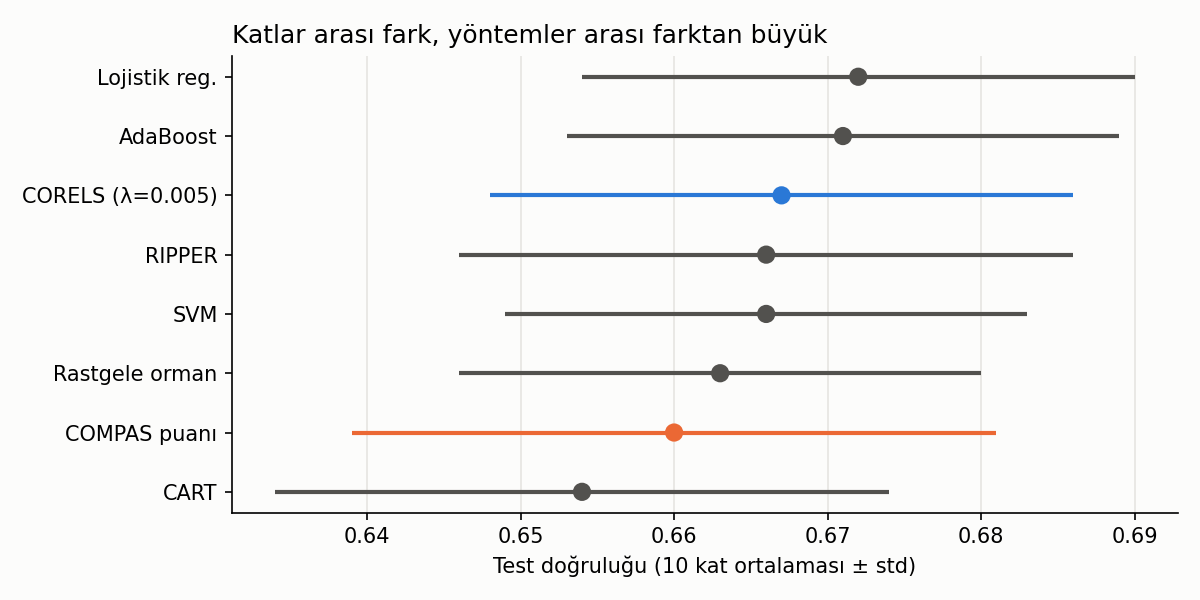

In [8]:
display(figurler.tablo_rakip()); figurler.sekil1(); display(Image("sekiller/sekil1_kiyaslama.png"))

## 6. Irka göre oranlar (Şekil 7)

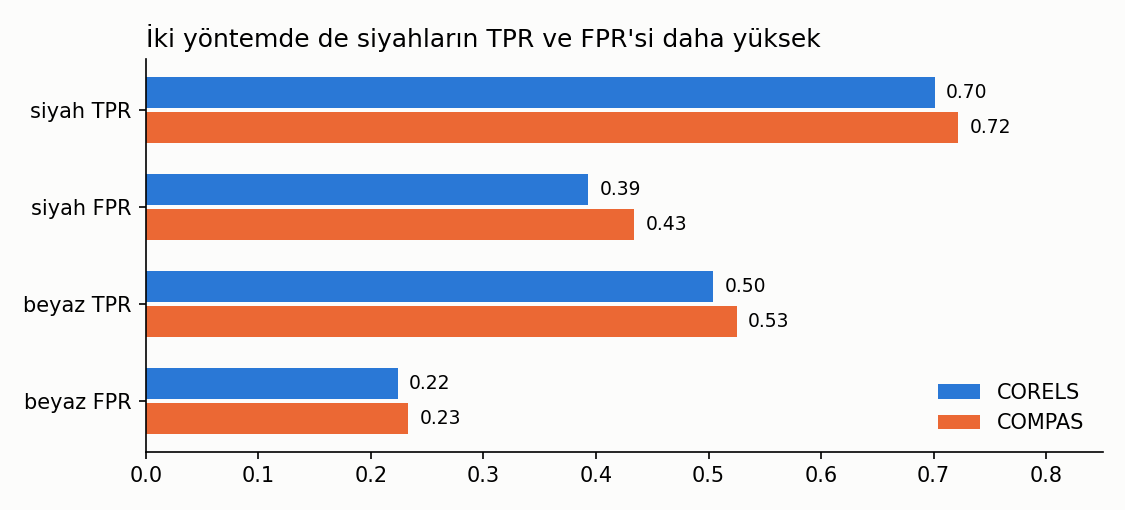

,CORELS,COMPAS
siyah TPR,0.701,0.722
siyah FPR,0.393,0.434
beyaz TPR,0.504,0.525
beyaz FPR,0.224,0.233


In [9]:
figurler.sekil2(); display(Image("sekiller/sekil2_irk.png")); figurler.tablo_irk()

## 7. Kararlılık: 100 bootstrap (λ = 0,005)

{'aynı kural kümesi %': 60.0, 'farklı kural kümesi sayısı': 21, 'kural sayısı': {2: 2, 3: 70, 4: 28}, 'kanıtlı %': 100.0}


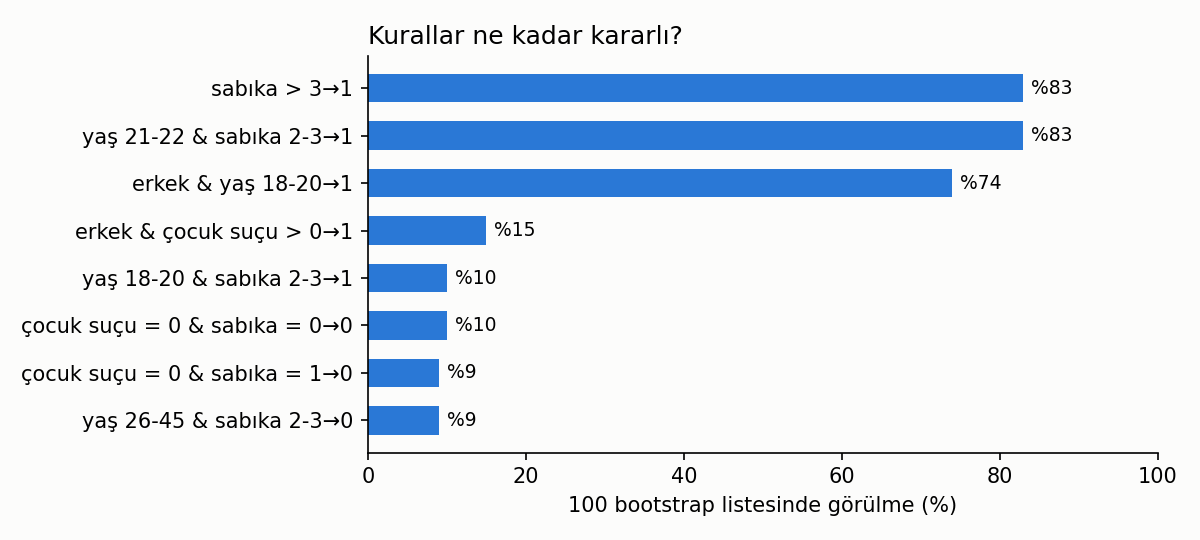

In [10]:
print(figurler.bootstrap_ozet()); figurler.sekil3(); display(Image("sekiller/sekil3_kararlilik.png"))

Katların hepsi aynı listeyi verdi, ama bootstrap'ta aynı kural kümesi yalnızca %60.

## 8. Kendi verim: okul terki (UCI 697)
1. dönem bilgisi; kayıtsız ve sınava girmemiş öğrenciler çıkarıldı. Eşikler yalnızca eğitim katından.

In [11]:
figurler.tablo_kendi()

,dogruluk,TPR,FPR,kural,kanit
yontem,,,,,
Lojistik reg.,0.840 ± 0.019,0.629,0.073,NaN,NaN
RIPPER,0.825 ± 0.021,0.580,0.074,NaN,NaN
CART,0.824 ± 0.019,0.674,0.114,NaN,NaN
Rastgele orman,0.820 ± 0.018,0.615,0.096,NaN,NaN
CORELS λ=0.02,0.818 ± 0.018,0.572,0.082,2.0,0.0
CORELS λ=0.03,0.802 ± 0.030,0.548,0.093,1.7,1.0
Çoğunluk,0.712 ± 0.020,0.000,0.000,NaN,NaN


λ = 0,02'de 10 katın hiçbirinde kanıt tamamlanmadı: **kesinlik ölçeklenmiyor** (kısmen Python uygulamamızın yavaşlığı).

## 9. Sonuç
- Ana sayılar yeniden üretildi (0,667 ve 0,660).
- CORELS kazanan değil, **eşit doğrulukta en kısa** model.
- Yaş tanımı, kutular ve λ, kanıtın dışında kalan kararlardır.
- Irk modelde olmasa da FPR farkı sürüyor.